In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.14.1+cu130
CUDA available: True
Device: cuda
GPU: Tesla T4


instalare biblioteci

In [ ]:

%pip install -q medmnist grad-cam scikit-learn seaborn


In [ ]:

import medmnist
from medmnist import PneumoniaMNIST

# Informatii despre dataset
info = medmnist.INFO["pneumoniamnist"]

print("Dataset:", info["description"])
print("Clase:", info["label"])
print("Numar canale:", info["n_channels"])

# Descarcam cele trei seturi
train_dataset = PneumoniaMNIST(
    split="train",
    download=True
)

val_dataset = PneumoniaMNIST(
    split="val",
    download=True
)

test_dataset = PneumoniaMNIST(
    split="test",
    download=True
)

print("\nDataset incarcat cu succes!")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Dataset: The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.
Clase: {'0': 'normal', '1': 'pneumonia'}
Numar canale: 1


100%|██████████| 4.17M/4.17M [00:07<00:00, 574kB/s]



Dataset incarcat cu succes!
Train: 4708
Validation: 524
Test: 624


Primele Radiografii

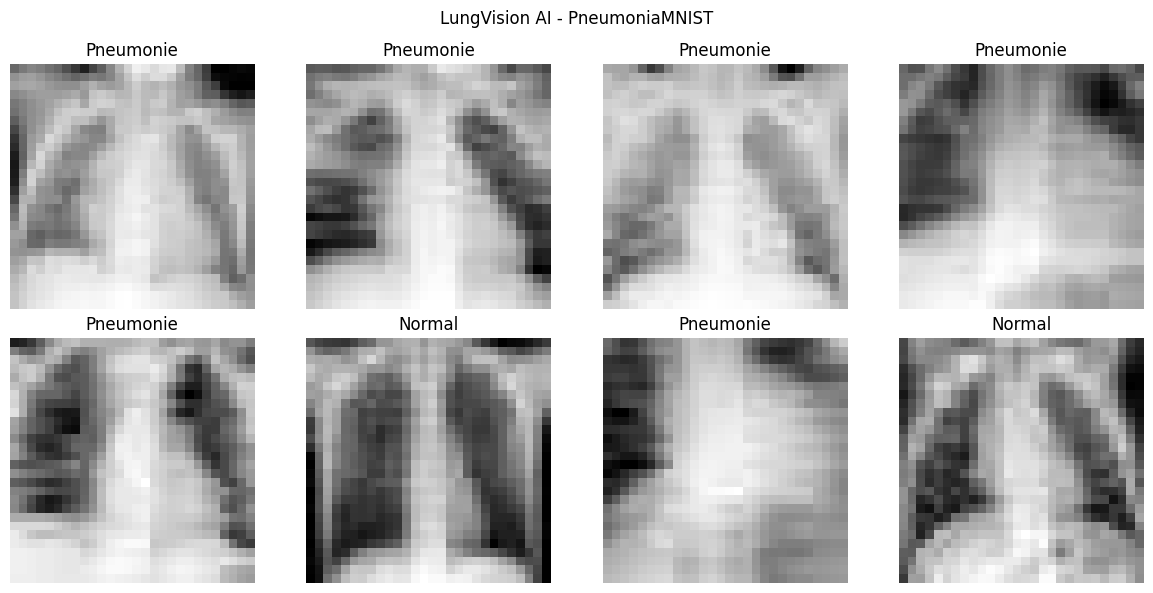

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image, cmap="gray")
    ax.set_title(
        "Pneumonie" if int(label[0]) == 1 else "Normal"
    )
    ax.axis("off")

plt.suptitle("LungVision AI - PneumoniaMNIST")
plt.tight_layout()
plt.show()


Transformarile imaginilor

In [ ]:

import torch
from torchvision import transforms
from torch.utils.data import DataLoader
from medmnist import PneumoniaMNIST

# Transformari pentru DenseNet121 preantrenat
image_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Incarcam imaginile la rezolutia 224x224
train_data = PneumoniaMNIST(
    split="train",
    size=224,
    transform=image_transform,
    download=True
)

val_data = PneumoniaMNIST(
    split="val",
    size=224,
    transform=image_transform,
    download=True
)

test_data = PneumoniaMNIST(
    split="test",
    size=224,
    transform=image_transform,
    download=True
)

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))


100%|██████████| 214M/214M [02:11<00:00, 1.63MB/s]


Train: 4708
Validation: 524
Test: 624


DataLoaders

In [ ]:

BATCH_SIZE = 32

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)


Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32, 1])
Images dtype: torch.float32


Verificam Distributia claselor

In [ ]:

import numpy as np

train_labels = train_data.labels.flatten()
val_labels = val_data.labels.flatten()

print("TRAIN")
print("Normal:", np.sum(train_labels == 0))
print("Pneumonie:", np.sum(train_labels == 1))

print("\nVALIDATION")
print("Normal:", np.sum(val_labels == 0))
print("Pneumonie:", np.sum(val_labels == 1))


TRAIN
Normal: 1214
Pneumonie: 3494

VALIDATION
Normal: 135
Pneumonie: 389


Incarcam modelul

In [ ]:

import torch
import torch.nn as nn
from torchvision import models

# Incarcam DenseNet121 preantrenat pe ImageNet
model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

# Inlocuim ultimul strat pentru clasificare binara
num_features = model.classifier.in_features

model.classifier = nn.Linear(num_features, 1)

# Mutam modelul pe GPU
model = model.to(device)

print("Model: DenseNet121")
print("Ultimul strat:", model.classifier)
print("Device:", next(model.parameters()).device)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 86.7MB/s]


Model: DenseNet121
Ultimul strat: Linear(in_features=1024, out_features=1, bias=True)
Device: cuda:0


Configurare antrenare

In [ ]:

# Inghetam straturile preantrenate
for param in model.features.parameters():
    param.requires_grad = False

# Pondere pentru clasa pozitiva (pneumonie)
normal_count = 1214
pneumonia_count = 3494

pos_weight = torch.tensor(
    [normal_count / pneumonia_count],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

EPOCHS = 5

print("Loss:", criterion)
print("Optimizer: Adam")
print("Epochs:", EPOCHS)
print("Positive class weight:", pos_weight.item())


Loss: BCEWithLogitsLoss()
Optimizer: Adam
Epochs: 5
Positive class weight: 0.3474527895450592


Pregatire antrenare


In [ ]:

from sklearn.metrics import roc_auc_score

train_losses = []
val_losses = []
val_aucs = []

best_auc = -1.0

for epoch in range(EPOCHS):

    # TRAIN
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.float().to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    # VALIDATION
    model.eval()
    val_loss_total = 0.0
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.float().to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            probs = torch.sigmoid(outputs)

            val_loss_total += loss.item() * images.size(0)
            all_probs.extend(probs.cpu().numpy().flatten())
            all_labels.extend(labels.cpu().numpy().flatten())

    val_loss = val_loss_total / len(val_loader.dataset)
    val_auc = roc_auc_score(all_labels, all_probs)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_aucs.append(val_auc)

    if val_auc > best_auc:
        best_auc = val_auc
        torch.save(model.state_dict(), MODEL_PATH)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val AUC: {val_auc:.4f}"
    )

print("\nBest Validation AUC:", round(best_auc, 4))


NameError: name 'MODEL_PATH' is not defined

In [ ]:

from google.colab import drive
import os

# Conectam Google Drive
drive.mount("/content/drive")

# Cream folderul pentru model
SAVE_DIR = "/content/drive/MyDrive/WWHealth/ai/models"
os.makedirs(SAVE_DIR, exist_ok=True)

# Definim calea modelului
MODEL_PATH = os.path.join(
    SAVE_DIR,
    "lungvision_best.pth"
)

print("Modelul va fi salvat in:", MODEL_PATH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modelul va fi salvat in: /content/drive/MyDrive/WWHealth/ai/models/lungvision_best.pth


Evaluarea modelului pe validation
Accuracy, Precision, Recall, F1 și Confusion Matrix

VALIDATION RESULTS
------------------
Accuracy: 0.9466
Precision: 0.9918
Recall: 0.9357
F1: 0.963
ROC-AUC: 0.99


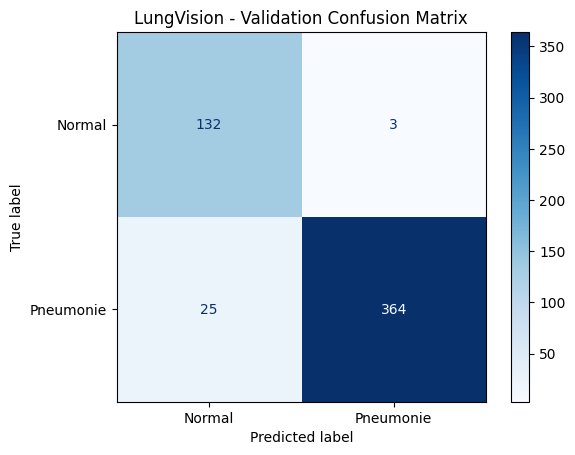

In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# Incarcam cel mai bun model salvat
model.load_state_dict(
    torch.load(
        "lungvision_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        probs = torch.sigmoid(outputs)

        all_probs.extend(
            probs.cpu().numpy().flatten()
        )
        all_labels.extend(
            labels.numpy().flatten()
        )

all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

# Prag initial de clasificare
threshold = 0.5
predictions = (all_probs >= threshold).astype(int)

print("VALIDATION RESULTS")
print("------------------")
print("Accuracy:",
      round(accuracy_score(all_labels, predictions), 4))
print("Precision:",
      round(precision_score(all_labels, predictions), 4))
print("Recall:",
      round(recall_score(all_labels, predictions), 4))
print("F1:",
      round(f1_score(all_labels, predictions), 4))
print("ROC-AUC:",
      round(roc_auc_score(all_labels, all_probs), 4))

# Confusion Matrix
cm = confusion_matrix(
    all_labels,
    predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonie"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("LungVision - Validation Confusion Matrix")
plt.show()


Comparare praguri pentru ca modelul rateaza 29 de cazuri de pneumonie...

In [ ]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
results = []

for threshold in thresholds:
    preds = (all_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        all_labels, preds, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": round(
            precision_score(all_labels, preds, zero_division=0), 4
        ),
        "Recall": round(
            recall_score(all_labels, preds, zero_division=0), 4
        ),
        "F1": round(
            f1_score(all_labels, preds, zero_division=0), 4
        ),
        "False Negatives": fn,
        "False Positives": fp
    })

df = pd.DataFrame(results)
display(df)


,Threshold,Precision,Recall,F1,False Negatives,False Positives
0,0.2,0.9574,0.9820,0.9695,7,17
1,0.3,0.9717,0.9717,0.9717,11,11
2,0.4,0.9841,0.9563,0.9700,17,6
3,0.5,0.9918,0.9357,0.9630,25,3
4,0.6,0.9972,0.9203,0.9572,31,1
5,0.7,0.9971,0.8689,0.9286,51,1


Am ales pragul 0.3 pentru ca sunt doar 14 pneumonii ratate si 8 alarme false

Fixarea noului prag si evaluare pe TEST

FINAL TEST RESULTS
------------------
Accuracy: 0.9071
Precision: 0.879
Recall: 0.9872
F1: 0.93
ROC-AUC: 0.9729


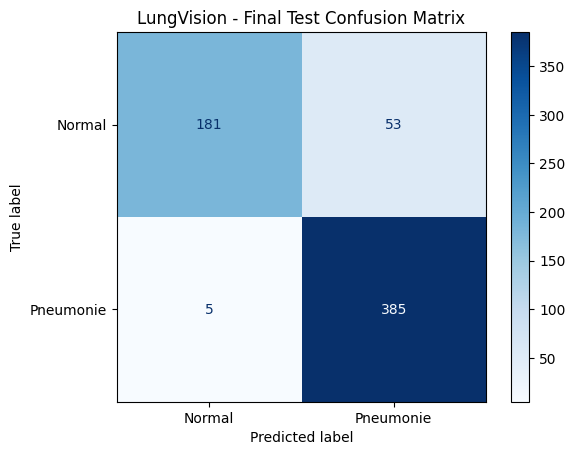

In [ ]:

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Pragul ales pe validation
THRESHOLD = 0.3

# Incarcam cel mai bun model
model.load_state_dict(
    torch.load(
        "lungvision_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

test_labels = []
test_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probs = torch.sigmoid(outputs)

        test_probs.extend(
            probs.cpu().numpy().flatten()
        )
        test_labels.extend(
            labels.numpy().flatten()
        )

test_labels = np.array(test_labels)
test_probs = np.array(test_probs)

test_preds = (test_probs >= THRESHOLD).astype(int)

print("FINAL TEST RESULTS")
print("------------------")
print("Accuracy:", round(accuracy_score(test_labels, test_preds), 4))
print("Precision:", round(precision_score(test_labels, test_preds), 4))
print("Recall:", round(recall_score(test_labels, test_preds), 4))
print("F1:", round(f1_score(test_labels, test_preds), 4))
print("ROC-AUC:", round(roc_auc_score(test_labels, test_probs), 4))

cm = confusion_matrix(test_labels, test_preds, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonie"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("LungVision - Final Test Confusion Matrix")
plt.show()
#Testul trebuie să rămână independent, ca să obținem o estimare mai realistă a performanței pe imagini nevăzute în timpul antrenării.

Pregătim Grad-CAM

In [ ]:

%pip install -q grad-cam


In [ ]:

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("Grad-CAM instalat corect!")


Grad-CAM instalat corect!


In [ ]:

import os

print("Model salvat:", os.path.exists("lungvision_best.pth"))
print("Fisiere disponibile:", os.listdir("."))


Model salvat: True
Fisiere disponibile: ['.config', 'lungvision_best.pth', 'drive', 'sample_data']


In [ ]:

from google.colab import drive
import os

drive.mount("/content/drive")

# Cautam modelul in Google Drive
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "lungvision_best.pth" in files:
        print("MODEL GASIT:", os.path.join(root, "lungvision_best.pth"))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Incarcam modelul final
model.load_state_dict(
    torch.load(
        "lungvision_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

# Ultimul bloc de feature extraction
target_layers = [model.features.norm5]

cam = GradCAM(
    model=model,
    target_layers=target_layers
)

print("Grad-CAM initializat!")


Grad-CAM initializat!


Generăm prima explicație vizuală

In [ ]:

import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Modelul ramane in modul evaluare
model.eval()

# Permitem calcularea gradientelor pentru Grad-CAM
for param in model.parameters():
    param.requires_grad_(True)

# Alegem ultimul strat de caracteristici
target_layers = [model.features.norm5]

# Initializam Grad-CAM
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

print("Grad-CAM pregatit!")
print("Gradiente activate:",
      model.features.norm5.weight.requires_grad)


Grad-CAM pregatit!
Gradiente activate: True


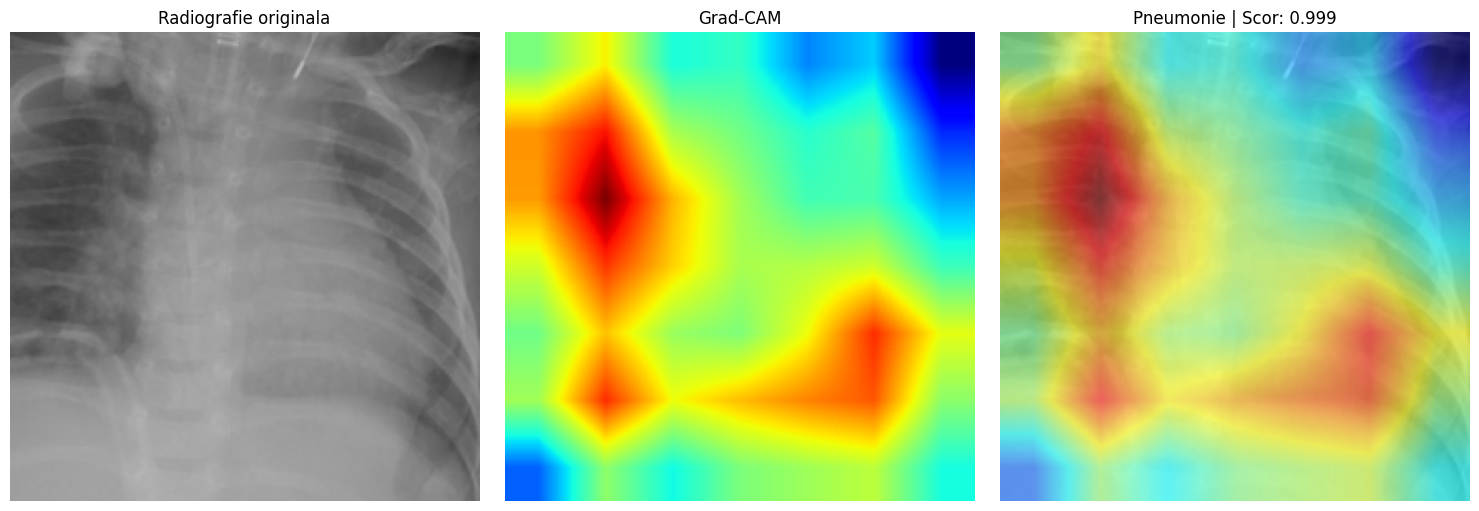

Eticheta reala: Pneumonie
Scor model: 0.9988


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import torch

# Alegem prima radiografie cu pneumonie din validation
index = next(
    i for i in range(len(val_data))
    if int(val_data.labels[i][0]) == 1
)

image_tensor, label = val_data[index]
input_tensor = image_tensor.unsqueeze(0).to(device)

# Generam Grad-CAM cu gradientele activate
with torch.enable_grad():
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(0)]
    )[0]

# Refacem imaginea originala din tensorul normalizat
image_np = image_tensor.permute(1, 2, 0).cpu().numpy()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_np = image_np * std + mean
image_np = np.clip(image_np, 0, 1).astype(np.float32)

# Suprapunem heatmap-ul peste radiografie
overlay = show_cam_on_image(
    image_np,
    grayscale_cam,
    use_rgb=True
)

# Calculam scorul modelului
with torch.no_grad():
    output = model(input_tensor)
    probability = torch.sigmoid(output).item()

prediction = "Pneumonie" if probability >= 0.3 else "Normal"

# Afisam rezultatele
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_np)
axes[0].set_title("Radiografie originala")

axes[1].imshow(grayscale_cam, cmap="jet")
axes[1].set_title("Grad-CAM")

axes[2].imshow(overlay)
axes[2].set_title(
    f"{prediction} | Scor: {probability:.3f}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Eticheta reala:", "Pneumonie" if int(label[0]) == 1 else "Normal")
print(f"Scor model: {probability:.4f}")
